# Guía L2 — El índice sancocho · **Sesión 1: la receta como función**

**Cálculo Diferencial — Laboratorio computacional** · Universidad Nacional de Colombia, Sede Manizales

> Esta idea nació un domingo en Berlín, entre un döner y el recuerdo de una bullabesa. La historia completa está en la guía: este cuaderno es la sobremesa vuelta código.

**Uso en Colab:** guarden su copia (`Archivo → Guardar una copia en Drive`) y renómbrenla `L2_apellidos.ipynb`. Las celdas marcadas con ✏️ invitan a explorar o modificar; las marcadas con 🗣️ son para escribir conclusiones del equipo.

---
## ⏸️ Momento 1 — Predecir

Antes de ejecutar, respondan P1, P2 y P3 de la guía en papel: el costo del sancocho para seis en Manizales, si manda el espinazo o el resto de la olla, y si subió más la papa o el plátano. Foto al informe.

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

# Precios mayoristas mensuales de SIPSA-DANE, congelados por el curso.
# El archivo .csv.gz se lee directamente: pandas reconoce la compresión.
RUTA = (
    "https://raw.githubusercontent.com/cmorregof/labs-calculo-2026-2/"
    "main/datos/sipsa_mensual.csv.gz"
)
df = pd.read_csv(RUTA)

print("Filas y columnas:", df.shape)
df.head(8)

Filas y columnas: (666865, 5)


,fecha,ciudad,mercado,producto,precio_kg
0,2013-01,Armenia,"Armenia, Frigocafé",Carne de cerdo en canal,6320.0
1,2013-01,Armenia,"Armenia, Frigocafé","Carne de cerdo, brazo con hueso",8520.0
2,2013-01,Armenia,"Armenia, Frigocafé","Carne de cerdo, brazo sin hueso",9000.0
3,2013-01,Armenia,"Armenia, Frigocafé","Carne de cerdo, cabeza de lomo",9020.0
4,2013-01,Armenia,"Armenia, Frigocafé","Carne de cerdo, costilla",9020.0
5,2013-01,Armenia,"Armenia, Frigocafé","Carne de cerdo, espinazo",6520.0
6,2013-01,Armenia,"Armenia, Frigocafé","Carne de cerdo, lomo con hueso",11020.0
7,2013-01,Armenia,"Armenia, Frigocafé","Carne de cerdo, lomo sin hueso",12020.0


---
## 1 · El ritual, ya sin niñera

En L1 lo hicimos juntos; hoy es de ustedes. El objetivo es decidir qué valores acepta cada columna, buscar valores ilegales y entender el alcance del congelado. Después, busquen los nombres oficiales de los ingredientes: los datos no saben cómo los llamamos en la casa.

🗣️ Escriban como comentario sus decisiones sobre los valores faltantes, precios no positivos y filas repetidas. ¿Una fila por `(fecha, mercado, producto)` es lo esperado?

In [17]:
# ✏️ Ejercicio 1 — Completen la auditoría y dejen sus decisiones en comentarios.
print("Mercados distintos:", df["mercado"].nunique())
print("Productos distintos:", df["producto"].nunique())
print("Ciudades:", df["ciudad"].nunique())
print("Meses: de", df["fecha"].min(), "a", df["fecha"].max())
print("\nTipos de dato:\n", df.dtypes)
print("\nValores faltantes por columna:\n", df.isna().sum())
print("\nPrecios medios no positivos:", (df["precio_kg"] <= 0).sum())
print("Filas repetidas por fecha, mercado y producto:",
      df.duplicated(["fecha", "mercado", "producto"]).sum())
print("Nombres de ciudades: ",sorted(df["ciudad"].unique()))
mz = df[df["ciudad"] == "Manizales"]
print("Mercados en Manizales:", mz["mercado"].unique())



# fecha: texto con formato AAAA-MM. de 2013-01 a 2024-12, Está guardada como texto, no como fecha de pandas.
# ciudad: texto. Hay 71 nombres de ciudades.
# mercado: texto. Hay 112 mercados 
# producto: texto. Hay 385 productos distintos.
# precio_kg: número real positivo, en pesos colombianos por kilogramo.

# VALORES ILEGALES Y DECICIONES
# No hay valores faltanes, por lo tanto decido dejarlo tal como esta
# Hay 0 precios no positivos, de igual manera no hay que filtrar datos
# No hay filas repetidas. Sí es el resultado esperado ya que a cada valor de (fecha, mercado, producto) le corresponde un unico precio_kg

# ALCANCE DEL CONGELADO 
# Son precios mayoristas promedio mensuales de SIPSA-DANE (2013-2024), no precios
# de tienda ni de plaza minorista. Por eso el costo del sancocho saldrá más bajo
# que lo que uno paga en el mercado de la esquina.


Mercados distintos: 112
Productos distintos: 385
Ciudades: 71
Meses: de 2013-01 a 2024-12

Tipos de dato:
 fecha            str
ciudad           str
mercado          str
producto         str
precio_kg    float64
dtype: object

Valores faltantes por columna:
 fecha        0
ciudad       0
mercado      0
producto     0
precio_kg    0
dtype: int64

Precios medios no positivos: 0
Filas repetidas por fecha, mercado y producto: 0
Nombres de ciudades:  ['Ancuya (Nariño)', 'Ancuyá (Nariño)', 'Arauca (Arauca)', 'Armenia', 'Barranquilla', 'Bogotá', 'Bucaramanga', 'Buenaventura (Valle del Cauca)', 'Cali', 'Caparrapí (Cundinamarca)', 'Cartagena', 'Cartago (Valle del Cauca)', 'Charalá (Santander)', 'Chiquinquirá (Boyacá)', 'Consacá (Nariño)', 'Cúcuta', 'Duitama (Boyacá)', 'El Carmen de Viboral (Antioquia)', 'El Santuario (Antioquia)', 'Florencia (Caquetá)', 'Güepsa (Santander)', 'Ibagué', 'Ipiales (Nariño)', 'La Ceja (Antioquia)', 'La Dorada (Caldas)', 'La Parada (Norte de Santander)', 'La Unión (A

In [10]:
# ✏️ Ejercicio 2 — Cambien `busca` e iteren.
# Encuentren los nombres oficiales de espinazo, yuca, papa, mazorca y plátano verde.
# Luego restrinjan la búsqueda a Manizales: no todas las variedades se venden allí.
# ✏️ Ejercicio 2 — Búsqueda iterativa y compacta
ingredientes = ["espinazo", "Yuca", "Papa", "mazorca", "plátano"]

for busca in ingredientes:
    coincidencias = df.loc[
        (df["ciudad"] == "Manizales") &     
        df["producto"].str.contains(busca, case=False, na=False), 
        "producto"
    ].unique()
    
    print(f"Nombres oficiales para '{busca}': {', '.join(coincidencias)}")

# Pista para Manizales:
# df.loc[(df["ciudad"] == "Manizales") &
#        df["producto"].str.contains(busca, case=False, na=False), "producto"].unique()

Nombres oficiales para 'espinazo': Carne de cerdo, espinazo
Nombres oficiales para 'Yuca': Yuca ICA
Nombres oficiales para 'Papa': Carne de cerdo, tocino papada, Papa R-12 negra, Papa San Félix, Papa capira, Papa criolla limpia, Papa única, Papaya Maradol, Papa parda pastusa
Nombres oficiales para 'mazorca': Chócolo mazorca
Nombres oficiales para 'plátano': Plátano dominico hartón maduro, Plátano dominico hartón verde, Plátano guineo


---
## 2 · La receta en código

La receta oficial es para seis personas. Cada valor está en kilogramos, que es la unidad del mercado: 1,5 kg de espinazo, 1 kg de yuca, 1 kg de papa, 0,9 kg de mazorca y 1,4 kg de plátano. Traducir de unidades de cocina a kilogramos también es una función.

In [11]:
RECETA = {
    "Carne de cerdo, espinazo":       1.5,
    "Yuca ICA":                       1.0,
    "Papa capira":                    1.0,
    "Chócolo mazorca":                0.9,
    "Plátano dominico hartón verde":  1.4,
}
print("Ingredientes:", len(RECETA), "| Kilos totales:", sum(RECETA.values()))

# ✏️ Confirmen que cada nombre existe para Manizales antes de seguir.

Ingredientes: 5 | Kilos totales: 5.8


---
## 3 · El pipeline, pieza por pieza

Estas cuatro funciones son puras: reciben una tabla y sus parámetros, y devuelven una tabla o un número. No dependen de `df`, `RECETA` ni ninguna otra variable externa. Lean cada contrato, prueben cada función por separado y luego sigan el dato a través de la composición.

In [12]:
def filtrar_ciudad(tabla, ciudad):
    """tabla → tabla: conserva únicamente las filas de una ciudad."""
    return tabla.loc[tabla["ciudad"] == ciudad].copy()

t1 = filtrar_ciudad(df, "Manizales")
print("1. filtrar_ciudad:    ", df.shape, "->", t1.shape)


def filtrar_mes(tabla, fecha):
    """tabla → tabla: conserva únicamente el mes AAAA-MM indicado."""
    return tabla.loc[tabla["fecha"] == fecha].copy()

t2 = filtrar_mes(t1, "2024-12")
print("2. filtrar_mes:       ", t1.shape, "->", t2.shape)


def filtrar_productos(tabla, receta):
    """tabla → tabla: conserva los productos que aparecen en la receta."""
    return tabla.loc[tabla["producto"].isin(receta)].copy()

t3 = filtrar_productos(t2, RECETA)
print("3. filtrar_productos: ", t2.shape, "->", t3.shape)
print(t3[["producto", "precio_kg"]].to_string(index=False))


def costear(tabla, receta):
    """tabla → número: suma kilos × precio_kg de cada ingrediente."""
    precios = tabla.groupby("producto")["precio_kg"].mean()
    faltantes = [producto for producto in receta if producto not in precios]
    if faltantes:
        raise ValueError(f"Faltan ingredientes: {faltantes}")
    return sum(kilos * precios[producto] for producto, kilos in receta.items())

print("\n4. costear:           ", f"${costear(t3, RECETA):,.0f}")

# ✏️ ¿Por qué `.isin(receta)` sirve para varios productos y `== receta` no?
# ¿En qué situación habría varias filas del mismo ingrediente y por qué usamos `mean`?

# Respuesta 1:
    #`==` compara cada fila con un solo valor. Si lo comparamos con un diccionario ,
    # (que tiene 5 llaves) pandas no sabe qué hacer y da error. `.isin(receta)`pregunta, fila por fila.

#Respuesta 2: 
    #Cuando una ciudad tiene varios mercados el mismo
    # producto aparece una vez por mercado en el mismo mes. Para quedarnos con un
    # solo precio por ingrediente promediamos sin ponderar, que es la decisión de
    # modelación que explica la guía.  En Manizales hay un solo mercado, así que el
    # promedio no cambia nada.

1. filtrar_ciudad:     (666865, 5) -> (16936, 5)
2. filtrar_mes:        (16936, 5) -> (111, 5)
3. filtrar_productos:  (111, 5) -> (5, 5)
                     producto  precio_kg
     Carne de cerdo, espinazo    13500.0
              Chócolo mazorca     1273.0
                  Papa capira     2133.0
Plátano dominico hartón verde     2663.0
                     Yuca ICA     1377.0

4. costear:            $28,634


In [13]:
# Una función que fabrica la función compuesta.
def componer(*funciones):
    def compuesta(x):
        for funcion in funciones:
            x = funcion(x)
        return x
    return compuesta

CIUDAD = "Manizales"
MES = df.loc[df["ciudad"] == CIUDAD, "fecha"].max()

costo_sancocho = componer(
    lambda tabla: filtrar_ciudad(tabla, CIUDAD),
    lambda tabla: filtrar_mes(tabla, MES),
    lambda tabla: filtrar_productos(tabla, RECETA),
    lambda tabla: costear(tabla, RECETA),
)

print(f"Mercado del sancocho en {CIUDAD}, {MES}: ${costo_sancocho(df):,.0f}")

# ✏️ Dibujen el recorrido de `df` por las cuatro funciones.
# ¿Por qué una lambda permite fijar ciudad, mes y receta sin romper la pureza de las funciones?

#Rta:
#`componer` espera funciones de un solo argumento (la tabla). Cada lambda
# "congela" los otros parámetros (CIUDAD, MES, RECETA) y deja solo la tabla
# como entrada. Las funciones originales siguen siendo puras: la lambda es la
# que recuerda los parámetros, no ellas.

Mercado del sancocho en Manizales, 2024-12: $28,634


🗣️ **Confronten P1:** ¿quién tuvo el mejor ojo de mercado? Los datos son precios mayoristas de una central de abastos: ¿el mercado de la esquina cobraría más o menos y por qué?

Respuesta:
    Geronimo tuvo la deduccion mas acertada. El mercado de la esquina cobraria mas porque ellos compran a precio mayorista y elevan los precios para venderlos a precio minorista.

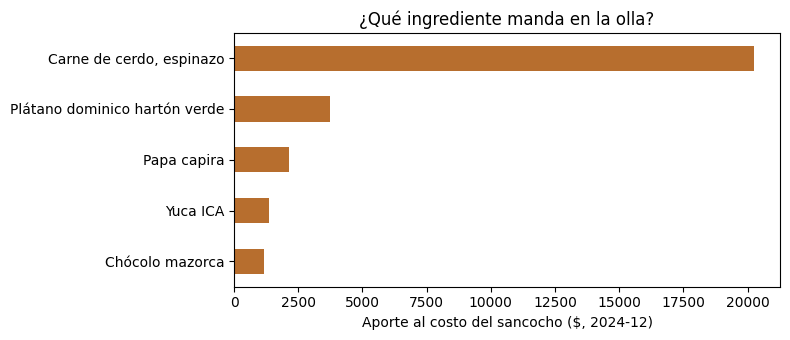

El espinazo aporta $20,250 de $28,634: 71% de la olla.
2024-01
                     producto  precio_kg
                  Papa capira     2018.0
Plátano dominico hartón verde     2193.0
  Costo papa + plátano: $5,088

2024-12
                     producto  precio_kg
                  Papa capira     2133.0
Plátano dominico hartón verde     2663.0
  Costo papa + plátano: $5,861

Cambio en pesos/kg:
 producto
Papa capira                      115.0
Plátano dominico hartón verde    470.0
dtype: float64

Cambio en %:
 producto
Papa capira                       5.7
Plátano dominico hartón verde    21.4
dtype: float64


In [14]:
# ¿Qué ingrediente manda? Confronten P2 con los aportes al costo.
mes_tabla = filtrar_productos(
    filtrar_mes(filtrar_ciudad(df, CIUDAD), MES), RECETA
)
precios_mes = mes_tabla.groupby("producto")["precio_kg"].mean()
aportes = pd.Series({
    producto: kilos * precios_mes[producto]
    for producto, kilos in RECETA.items()
}).sort_values()

ax = aportes.plot.barh(figsize=(8, 3.5), color="#B76E2E")
ax.set_xlabel(f"Aporte al costo del sancocho ($, {MES})")
ax.set_title("¿Qué ingrediente manda en la olla?")
plt.tight_layout()
plt.show()

total = aportes.sum()
espinazo = aportes["Carne de cerdo, espinazo"]
print(f"El espinazo aporta ${espinazo:,.0f} de ${total:,.0f}: {100 * espinazo / total:.0f}% de la olla.")

# ✏️ Para P3, cambien la receta a solo papa y plátano; comparen el primer y último mes.
RECETA_P3 = {
    "Papa capira":                    1.0,
    "Plátano dominico hartón verde":  1.4,
}

for mes in ["2024-01", "2024-12"]:
    tabla = filtrar_productos(filtrar_mes(filtrar_ciudad(df, "Manizales"), mes), RECETA_P3)
    print(mes)
    print(tabla[["producto", "precio_kg"]].to_string(index=False))
    print(f"  Costo papa + plátano: ${costear(tabla, RECETA_P3):,.0f}\n")

# Cambio de cada precio entre enero y diciembre de 2024
serie = (df[(df["ciudad"] == "Manizales") & df["producto"].isin(RECETA_P3)]
         .pivot_table(index="fecha", columns="producto", values="precio_kg"))
enero, diciembre = serie.loc["2024-01"], serie.loc["2024-12"]
print("Cambio en pesos/kg:\n", diciembre - enero)
print("\nCambio en %:\n", ((diciembre / enero - 1) * 100).round(1))


---
## 4 · Momento 3 — Explicar

🗣️ Media página del equipo: confronten P1 y P2, expliquen cómo decidieron los nombres oficiales y completen la frase: **«Un pipeline es una composición de funciones porque…»**

Para P1 apostamos que el sancocho para seis personas costaría unos $28.000 en diciembre de 2024, y el dato real de Manizales fue de $28.634, así que nos quedamos a menos de mil pesos de distancia. Pensamos en dos partes: calculamos que todos los ingredientes menos la carne costarían unos $10.000, porque a precio mayorista la papa, la yuca y el plátano son baratos, y que la carne costaría el doble de eso. Los datos mostraron que todo lo demás junto cuesta $8.384, un poco menos de lo que creíamos. En P2 apostamos que el espinazo sería el ingrediente más costoso y acertamos: se lleva $20.250 de los $28.634, es decir, 71 de cada 100 pesos de la olla, algo más del doble de lo que cuestan los otros cuatro ingredientes juntos. La sorpresa fue ver qué tan bien funcionó la intuición. Aun así, estos son precios de una central de abastos y no de una tienda de barrio, por eso lo que uno paga al comprar suelto en el mercado suele ser más alto.

Para elegir los nombres oficiales de los ingredientes, tuvimos en cuenta que los datos del DANE no usan los nombres de la casa. Buscamos cada palabra entre los productos de Manizales y escogimos el que corresponde a la receta. El espinazo, la yuca y la mazorca tenían un solo nombre posible: “Carne de cerdo, espinazo”, “Yuca ICA” y “Chócolo mazorca”. La papa tenía varias variedades y elegimos la papa capira, que es la de la receta. En el plátano había verde, maduro y guineo, y elegimos el “Plátano dominico hartón verde”, porque el sancocho lleva plátano verde. Después comprobamos que los cinco aparecen en los 144 meses entre 2013 y 2024, así que se puede calcular el costo de cualquier mes.

Un pipeline es una composición de funciones porque es una cadena de pasos en la que cada paso recibe lo que dejó el anterior y devuelve un solo resultado. En el sancocho, de toda la tabla de precios del país nos quedamos con Manizales, de ahí con diciembre de 2024, de ahí con los cinco ingredientes, y al final multiplicamos los kilos por el precio y sumamos. Cada paso es una función y el pipeline es todos ellos uno tras otro, igual que una receta en la que cada paso depende del anterior.


---
## 🤖 Protocolo de IA

Las reglas de siempre siguen vigentes: intento propio, la IA no es autoridad final y todo uso va en la bitácora individual. Para la cacería estrella pregunten a una IA, sin contexto: *«¿cuánto cuesta hacer un sancocho para seis personas en Colombia?»*. Guarden la respuesta y la fecha. En la sesión 2 la compararán con el índice construido sobre datos oficiales.

**Próxima sesión:** el índice en el tiempo, los picos históricos, el duelo de ciudades, la conmutatividad y la unidad sancocho. Averigüen antes qué ingredientes lleva el plato de su casa.